In [36]:
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.layers import BatchNormalization, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt

In [37]:
# Load MNIST dataset
x_train = np.load("mnist.npz/x_train.npy")
y_train = np.load("mnist.npz/y_train.npy")
x_test = np.load("mnist.npz/x_test.npy")
y_test = np.load("mnist.npz/y_test.npy")

print(x_train.shape)
print(y_train.shape) 
print(x_test.shape) 
print(y_test.shape) 

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [38]:
# Display unique labels

print("Unique train labels:", np.unique(y_train))

Unique train labels: [0 1 2 3 4 5 6 7 8 9]


The unique labels in the MNSIT dataset are:  [0 1 2 3 4 5 6 7 8 9]


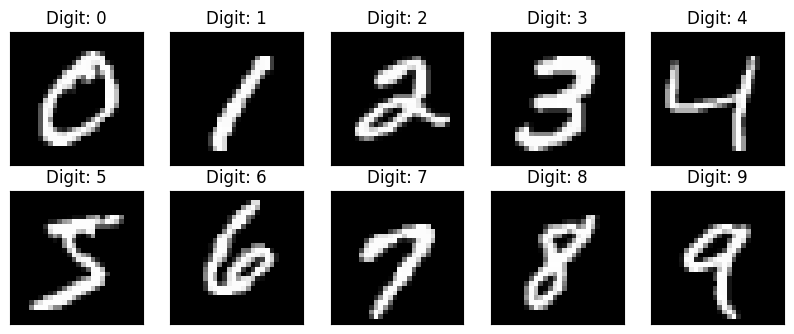

In [39]:
# Display MNIST images
unique_labels = np.unique(y_train)
print("The unique labels in the MNSIT dataset are: ",unique_labels)

plt.figure(figsize=(10,10))
for i in range(len(unique_labels)): 
    label = unique_labels[i]
    idx = np.where(y_train == label)[0][0]
    plt.subplot(5,5,i+1)
    plt.imshow(x_train[idx],cmap="gray")
    plt.title(f"Digit: {label}")
    plt.xticks([])
    plt.yticks([])
    # plt.grid(False)

# plt.tight_layout()
plt.show()

In [40]:
# Preprocess the images

# Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# Reshape images for CNN
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

Training data shape: (60000, 28, 28, 1)
Training labels shape: (60000,)


In [41]:
model = models.Sequential([

    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    Dropout(0.25),

    layers.Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),

    layers.Flatten(),
    # 64 neurons
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 26, 26, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_10 (Conv2D)                   │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 11, 11, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_11 (Conv2D)                   │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 3, 3, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_3 (Flatten)                  │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 64)                  │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,642 (365.79 KB)

 Non-trainable params: 320 (1.25 KB)

In [42]:
# Compile the model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [43]:
# Train the model

# Early stopping
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    x_train, y_train,
    epochs=50,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 12ms/step - accuracy: 0.9544 - loss: 0.1462 - val_accuracy: 0.9862 - val_loss: 0.0421
Epoch 2/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.9827 - loss: 0.0552 - val_accuracy: 0.9868 - val_loss: 0.0382
Epoch 3/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9863 - loss: 0.0414 - val_accuracy: 0.9880 - val_loss: 0.0411
Epoch 4/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 21s 12ms/step - accuracy: 0.9881 - loss: 0.0374 - val_accuracy: 0.9902 - val_loss: 0.0348
Epoch 5/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9907 - loss: 0.0276 - val_accuracy: 0.9912 - val_loss: 0.0322
Epoch 6/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.9910 - loss: 0.0271 - val_accuracy: 0.9907 - val_loss: 0.0331
Epoch 7/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9926 - loss: 0.0233 - val_accuracy: 0.9912 - val_loss: 0.0330
Epoch 8/50
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 19s 11ms/step - accuracy: 0.9931 -

In [44]:
# Evaluate training data
train_loss, train_acc = model.evaluate(x_train, y_train, verbose=0)

# Evaluate testing data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)

# Print results
print("Training Accuracy:", train_acc * 100, "%")
print("Training Loss:", train_loss)

print("Testing Accuracy:", test_acc * 100, "%")
print("Testing Loss:", test_loss)

Training Accuracy: 99.46666955947876 %
Training Loss: 0.01694299653172493
Testing Accuracy: 98.94000291824341 %
Testing Loss: 0.03418585658073425


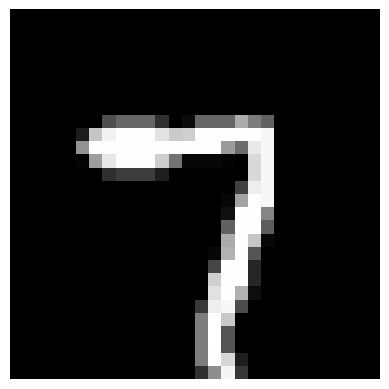

Predicted: 7
Actual: 7


In [45]:
# Take a random image from test dataset
n = np.random.randint(len(x_test))
image = x_test[n]

# Predict the image
prediction = model.predict(image.reshape(1, 28, 28, 1), verbose=0)

# Get predicted and actual class
predicted = np.argmax(prediction)
actual = int(y_test[n])

# Display the image
plt.imshow(image, cmap='gray')
plt.axis('off')
plt.show()

# Print prediction results
print("Predicted:", class_names[predicted])
print("Actual:", class_names[actual])

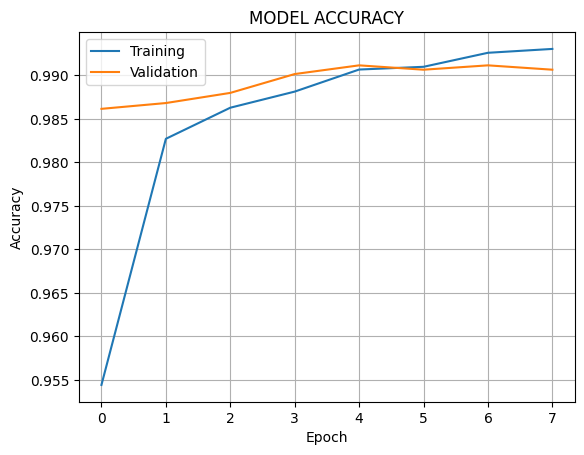

In [46]:
# Plot training and validation accuracy

plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.title('MODEL ACCURACY')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.xticks(range(len(history.history['accuracy'])))

plt.legend()
plt.grid()
plt.show()

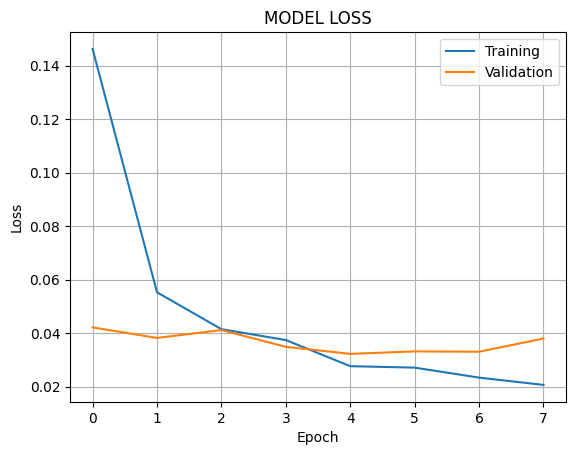

In [47]:
# Plot training and validation loss

plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')

plt.title('MODEL LOSS')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.xticks(range(len(history.history['loss'])))

plt.legend()
plt.grid()
plt.show()